# INF-8239 · Ejercicio 04 · Clasificador visual con CNN y Model Card

**Unidad 02 · Visión por computadora**

| Elemento | Definición |
|---|---|
| Tarea | Clasificar imágenes de prendas de 28×28 px en 10 clases (Fashion-MNIST) |
| Unidad de análisis | Una imagen en escala de grises |
| Métrica principal | F1 macro (todas las clases pesan igual) |
| Comparación | Línea base densa vs. CNN del proyecto base (pooling global) vs. CNN con capa densa |
| Regla de selección | Mayor F1 macro en **validación**; si la diferencia es < 1 punto, el más barato |

> Ejercicio académico. Las imágenes son productos de catálogo centrados sobre fondo uniforme; el modelo no está validado para fotografías reales.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import pandas as pd
from IPython.display import Image, display

REPORTS = ROOT / "reports"
print("Raíz:", ROOT)
print("Intérprete:", sys.executable)

Raíz: /tmp/cv/INF8239_U02_E04_CV
Intérprete: /tmp/cv/INF8239_U02_E04_CV/.venv/bin/python3


## 1. Obtención reproducible
Archivos IDX oficiales descargados desde GitHub en un commit fijado y verificados con SHA-256.

In [2]:
from scripts import download_data

assert download_data.main() == 0

OK  train-images-idx3-ubyte.gz  3aede38d61863908…
OK  train-labels-idx1-ubyte.gz  a04f17134ac03560…


OK  t10k-images-idx3-ubyte.gz  346e55b948d973a9…
OK  t10k-labels-idx1-ubyte.gz  67da17c76eaffca5…


## 2. Auditoría

In [3]:
from scripts import audit_data

audit = audit_data.run()
print(json.dumps({k: audit[k] for k in ["train_shape", "test_shape", "pixel_range", "pixel_mean",
                                        "blank_images", "exact_duplicates",
                                        "near_duplicates_test_vs_train"]}, indent=2))
pd.DataFrame(audit["class_counts"])

{
  "train_shape": [
    60000,
    28,
    28
  ],
  "test_shape": [
    10000,
    28,
    28
  ],
  "pixel_range": [
    0,
    255
  ],
  "pixel_mean": {
    "train": 0.2860405969887955,
    "test": 0.28684928071228494
  },
  "blank_images": 0,
  "exact_duplicates": {
    "within_train": 0,
    "within_test": 0,
    "test_in_train": 0
  },
  "near_duplicates_test_vs_train": {
    "threshold_rms_14x14": 0.02,
    "count": 10,
    "with_different_label": 0
  }
}


,train,test
T-shirt/top,6000,1000
Trouser,6000,1000
Pullover,6000,1000
Dress,6000,1000
Coat,6000,1000
Sandal,6000,1000
Shirt,6000,1000
Sneaker,6000,1000
Bag,6000,1000
Ankle boot,6000,1000


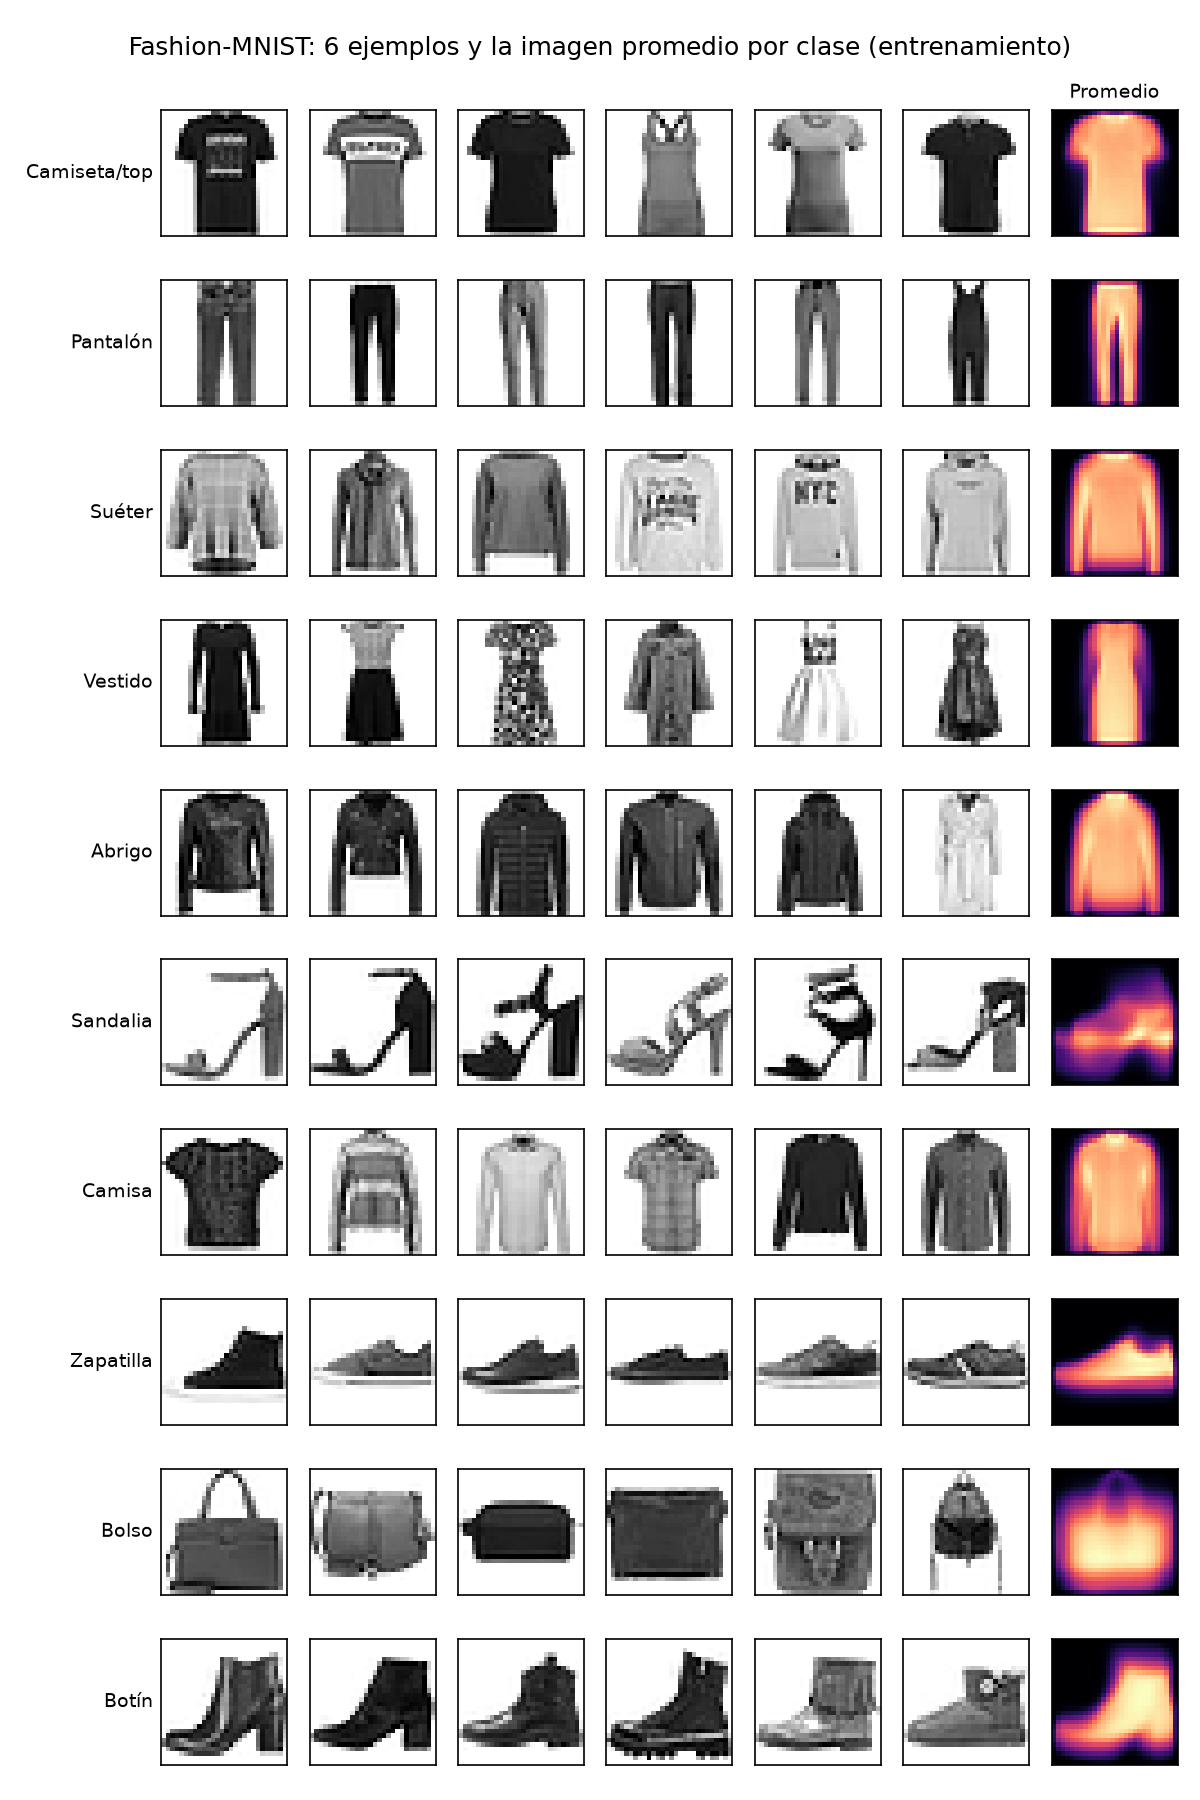

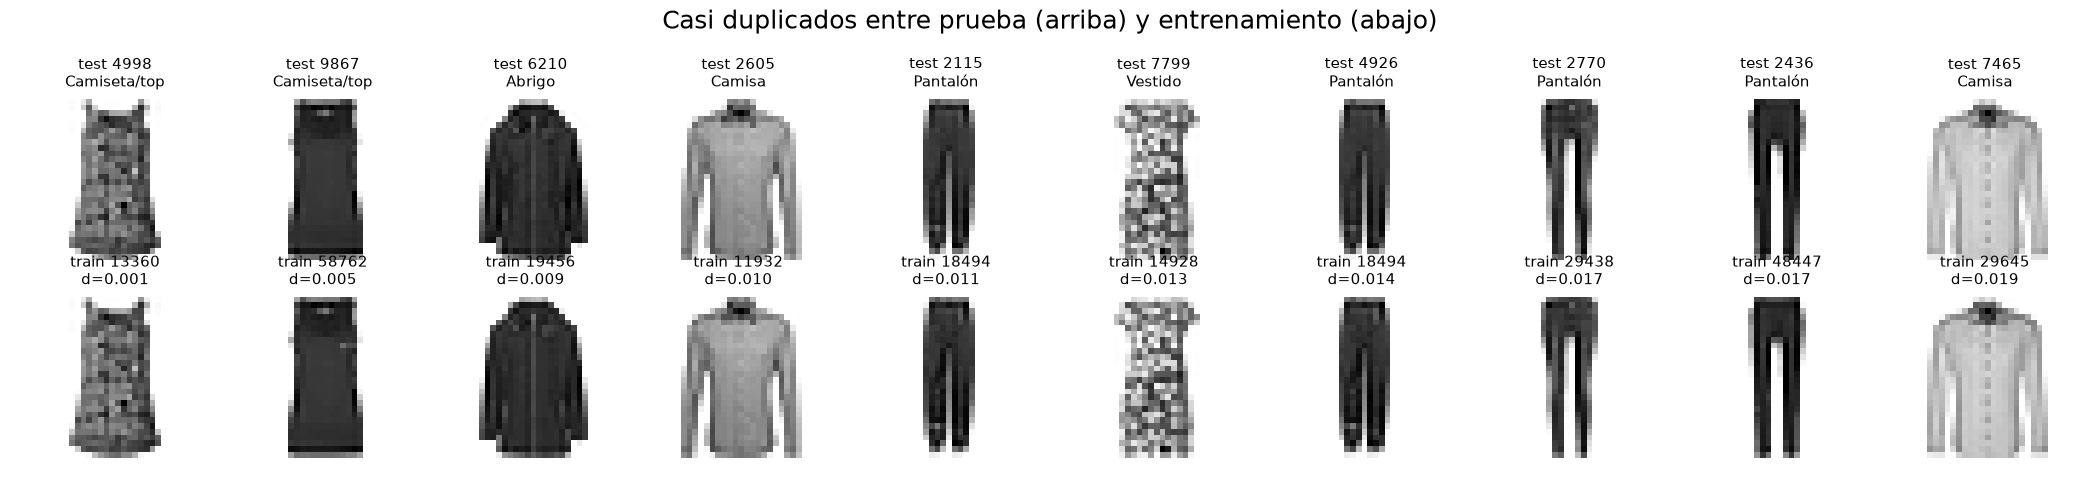

In [4]:
display(Image(REPORTS / "fig_audit_samples.png", width=600))
display(Image(REPORTS / "fig_audit_near_duplicates.png", width=900))

**Lectura.** Las 70 000 imágenes tienen forma 28×28, valores 0–255 y ninguna está en blanco. Las clases están perfectamente balanceadas (6 000 por clase en entrenamiento y 1 000 en prueba). No hay duplicados exactos, pero sí **casi duplicados** entre prueba y entrenamiento (la misma prenda con mínimas diferencias). Se excluyen de validación y prueba para no evaluar con imágenes prácticamente vistas.

## 3. Partición, entrenamiento y evaluación
Validación: 10 % estratificado del entrenamiento oficial (semilla 42). La prueba oficial se usa una sola vez. *En CPU este paso tarda varios minutos.*

In [5]:
from scripts import train_cv

results = train_cv.run(epochs=15)
print("Partición:", json.dumps({k: results["split"][k] for k in
      ["train", "valid", "test", "removed_near_duplicates_valid", "removed_near_duplicates_test",
       "train_index_sha256"]}, indent=2))

I0000 00:00:1791296643.489872     107 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791296643.497157     107 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791296675.261553     107 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791296675.264808     107 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1791296688.681117     107 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/15


E0000 00:00:1791296689.374984     107 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


...

E0000 00:00:1791297463.745487     107 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1791297472.638362     107 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1791297479.756323     107 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1791297484.924378     107 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Partición: {
  "train": 54000,
  "valid": 5993,
  "test": 9991,
  "removed_near_duplicates_valid": 7,
  "removed_near_duplicates_test": 9,
  "train_index_sha256": "f21e3d1771bfb0627b1aaf3ba7ea18691aaf02bb95dea0af96bbb17bdc62bb46"
}


In [6]:
cols = ["model", "parameters", "size_kb", "epochs_run", "best_epoch", "train_seconds",
        "batch_ms_per_image", "single_image_latency_ms", "valid_f1_macro", "test_accuracy",
        "test_f1_macro", "test_f1_ci95_low", "test_f1_ci95_high", "selected"]
print("Regla:", results["selection_rule"])
print("Seleccionado:", results["selected_model"])
print("McNemar densa vs seleccionado:", results["mcnemar_dense_vs_selected"])
print("McNemar cnn_gap vs cnn:", results["mcnemar_cnn_gap_vs_cnn"])
results["summary"][cols].round(4)

Regla: mayor F1 macro en validación; diferencia < 0.01 -> menor tiempo de entrenamiento
Seleccionado: cnn
McNemar densa vs seleccionado: {'only_a_correct': 183, 'only_b_correct': 667, 'p_value': 2.3543454667751247e-65}
McNemar cnn_gap vs cnn: {'only_a_correct': 201, 'only_b_correct': 1213, 'p_value': 1.8856220263251153e-176}


,model,parameters,size_kb,epochs_run,best_epoch,train_seconds,batch_ms_per_image,single_image_latency_ms,valid_f1_macro,test_accuracy,test_f1_macro,test_f1_ci95_low,test_f1_ci95_high,selected
0,dense,50890,619.1113,15,15,21.9628,0.0211,2.5914,0.8789,0.8737,0.8727,0.8664,0.8791,False
1,cnn_gap,19466,262.1650,15,15,303.9114,0.1353,5.9166,0.8205,0.8208,0.8194,0.8122,0.8258,False
2,cnn,220234,2619.7324,15,13,436.4999,0.1339,6.1009,0.9205,0.9221,0.9213,0.9161,0.9270,True


## 4. Curvas de aprendizaje

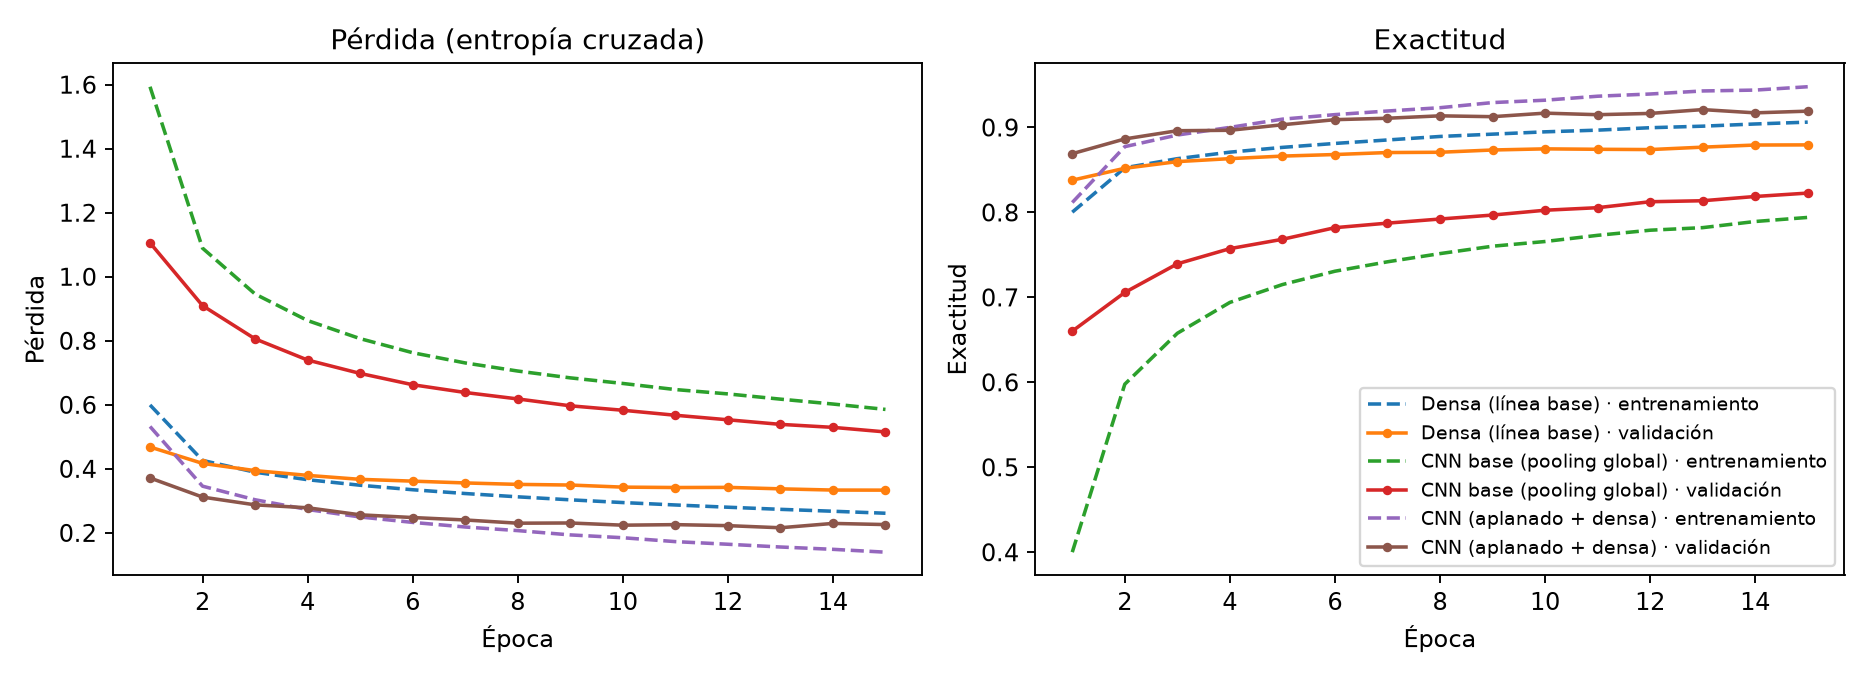

In [7]:
display(Image(REPORTS / "fig_learning_curves.png", width=900))

## 5. Métricas y errores por clase

,class,precision,recall,f1,support
0,T-shirt/top,0.844,0.925,0.883,998
1,Trouser,0.998,0.983,0.990,997
2,Pullover,0.899,0.863,0.881,1000
3,Dress,0.926,0.933,0.929,999
4,Coat,0.841,0.911,0.875,999
5,Sandal,0.992,0.973,0.982,1000
6,Shirt,0.818,0.705,0.757,998
7,Sneaker,0.959,0.972,0.965,1000
8,Bag,0.983,0.984,0.984,1000
9,Ankle boot,0.962,0.972,0.967,1000


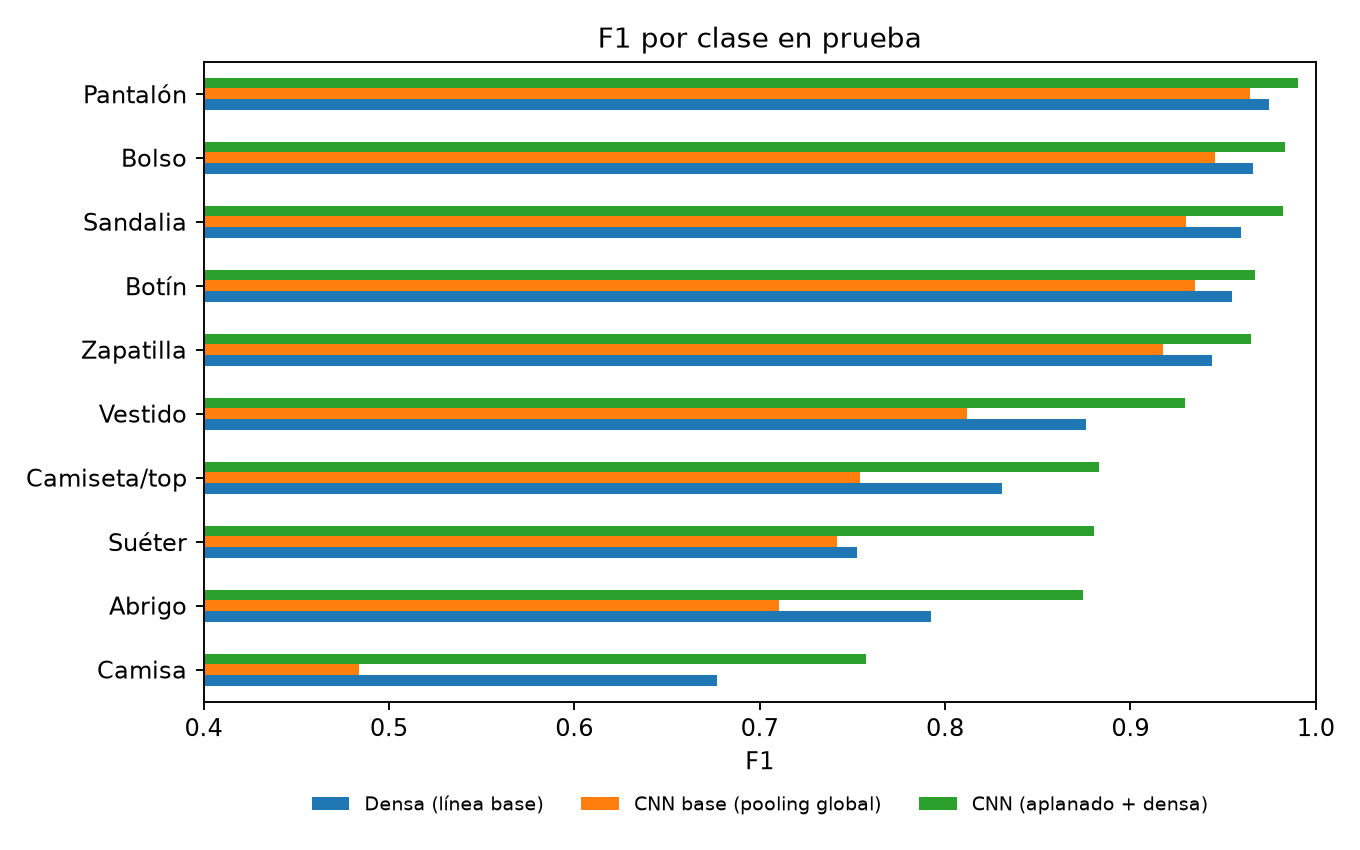

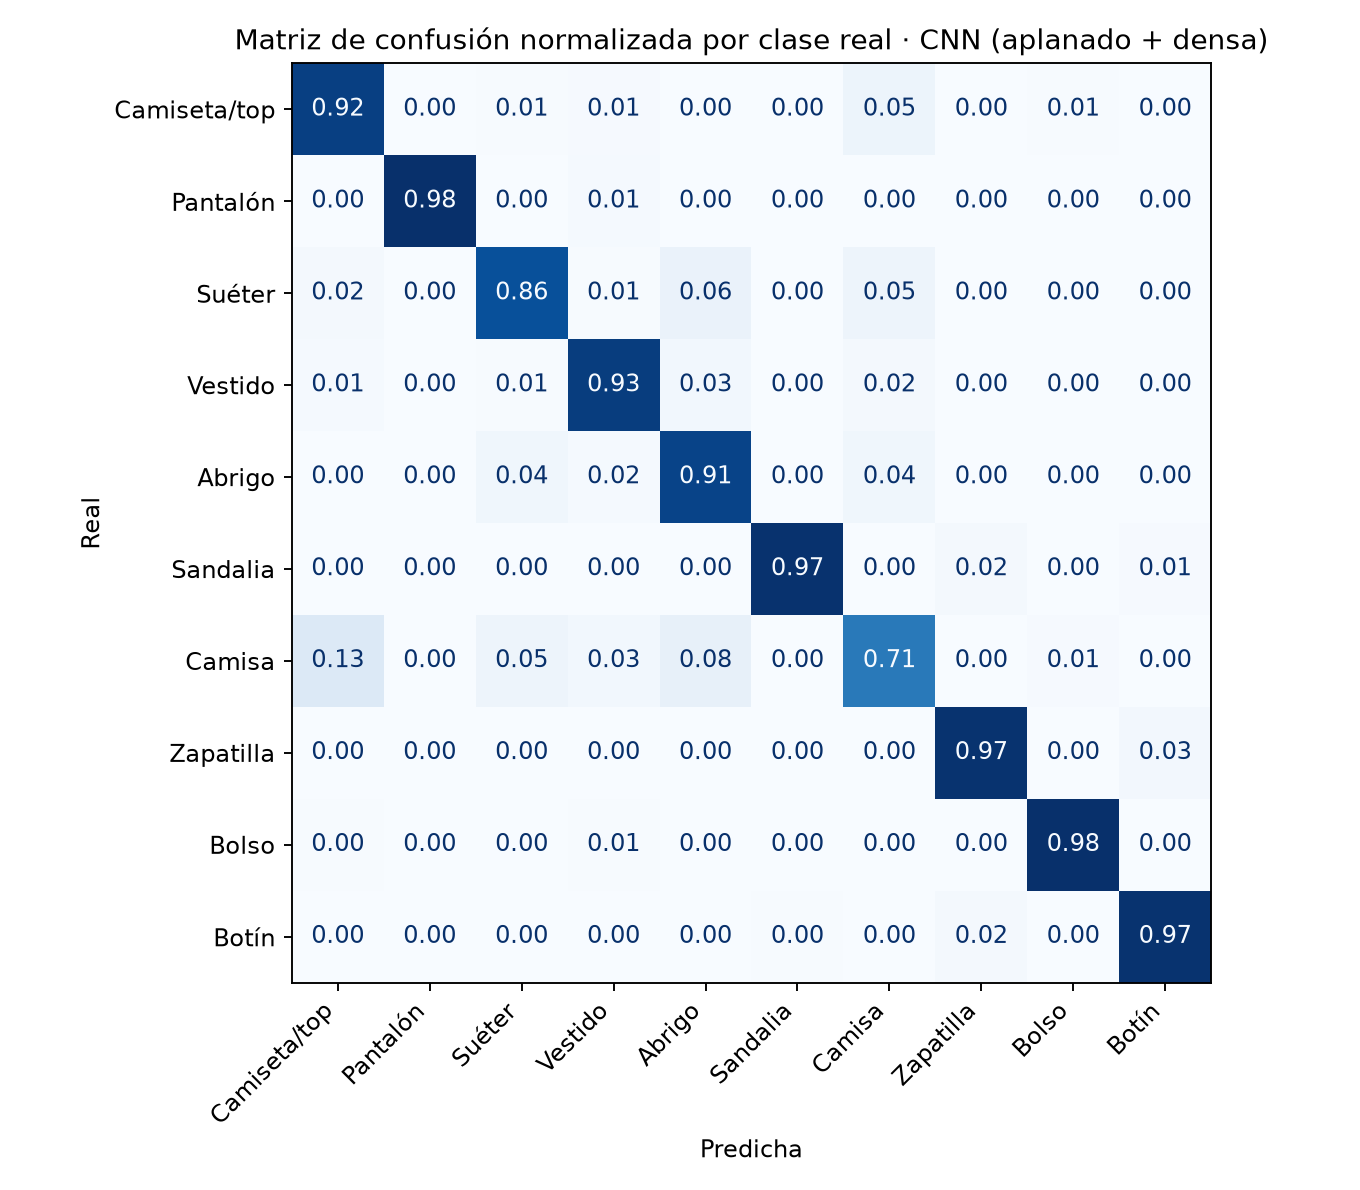

In [8]:
sel = results["selected_model"]
pc = results["per_class"]
display(pc[pc.model == sel][["class", "precision", "recall", "f1", "support"]].round(3))
display(Image(REPORTS / "fig_f1_per_class.png", width=700))
display(Image(REPORTS / f"fig_confusion_{sel}.png", width=700))

,true_id,pred_id,true,pred,count,share_of_true_class
0,6,0,Camisa,Camiseta/top,133,0.133
1,6,4,Camisa,Abrigo,78,0.078
2,2,4,Suéter,Abrigo,63,0.063
3,0,6,Camiseta/top,Camisa,51,0.051
4,2,6,Suéter,Camisa,48,0.048
5,6,2,Camisa,Suéter,48,0.048
6,4,6,Abrigo,Camisa,37,0.037
7,4,2,Abrigo,Suéter,35,0.035
8,3,4,Vestido,Abrigo,27,0.027
9,6,3,Camisa,Vestido,27,0.027


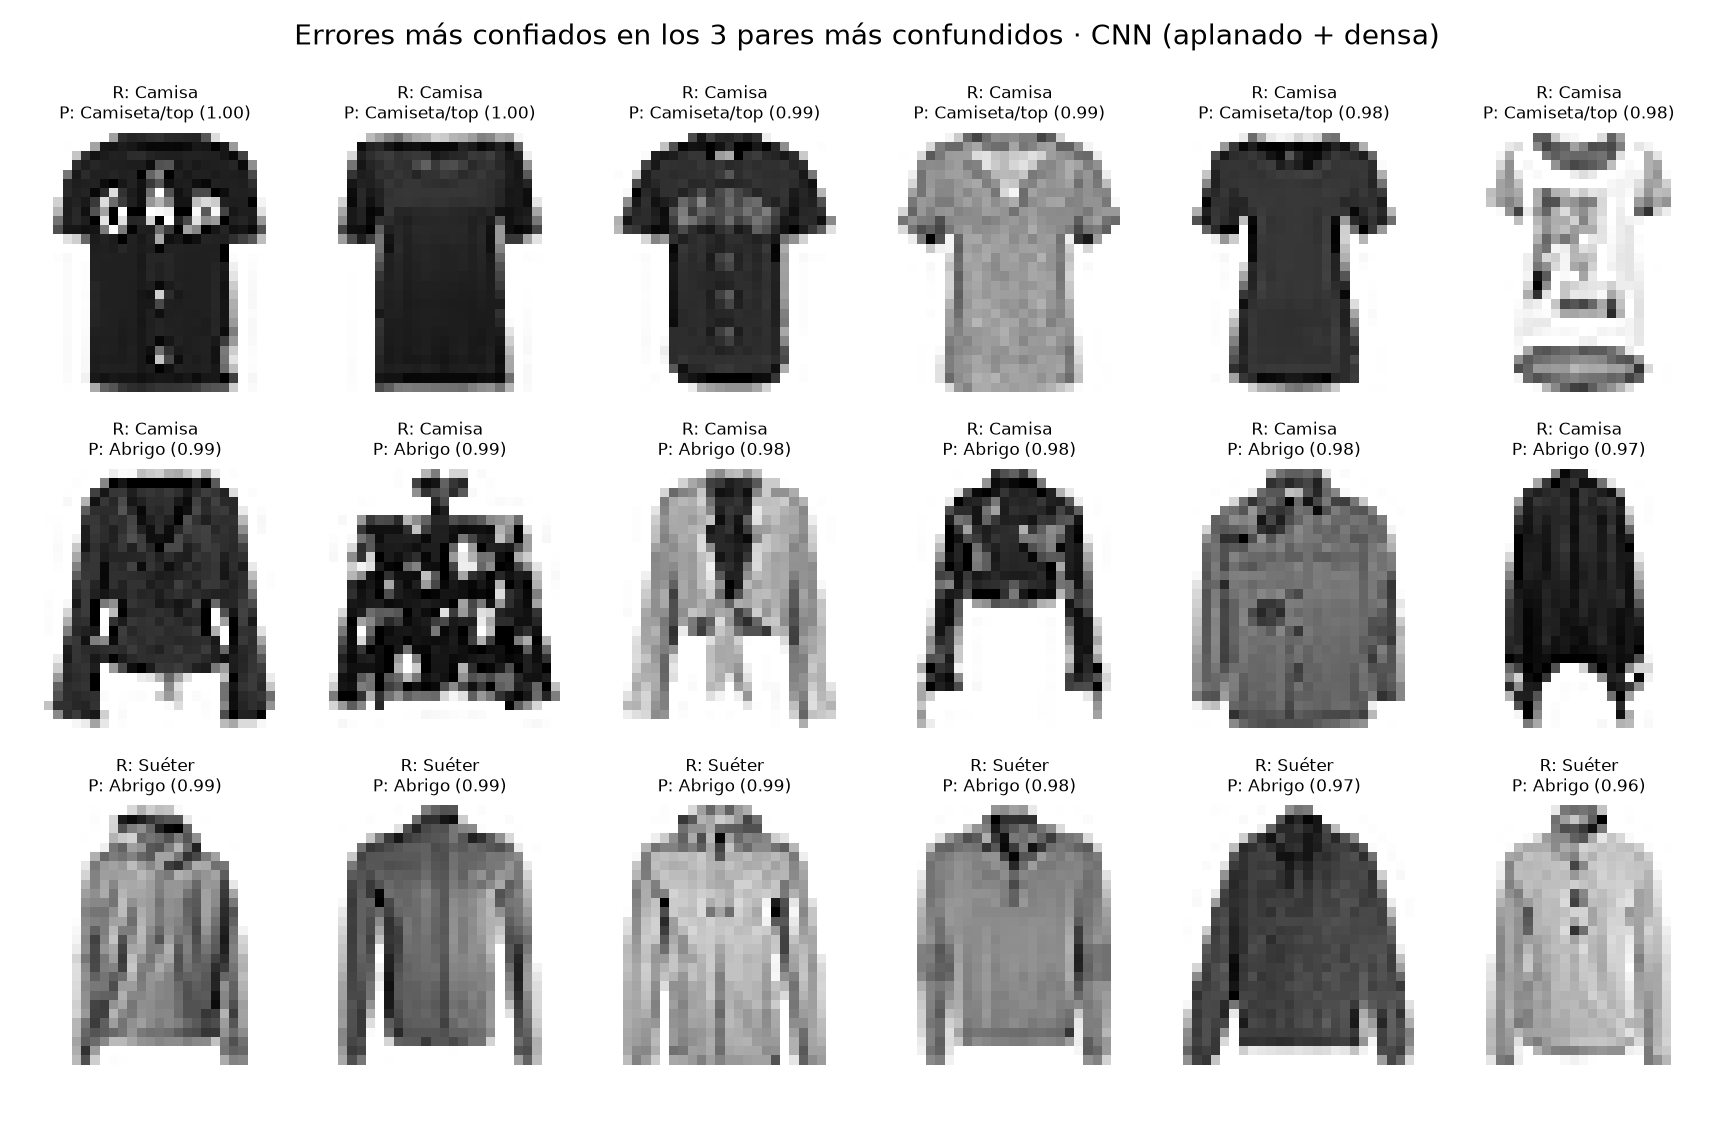

In [9]:
display(results["confusions"].round(3))
display(Image(REPORTS / f"fig_errors_{sel}.png", width=850))

## 6. Costo, tamaño y decisión técnica

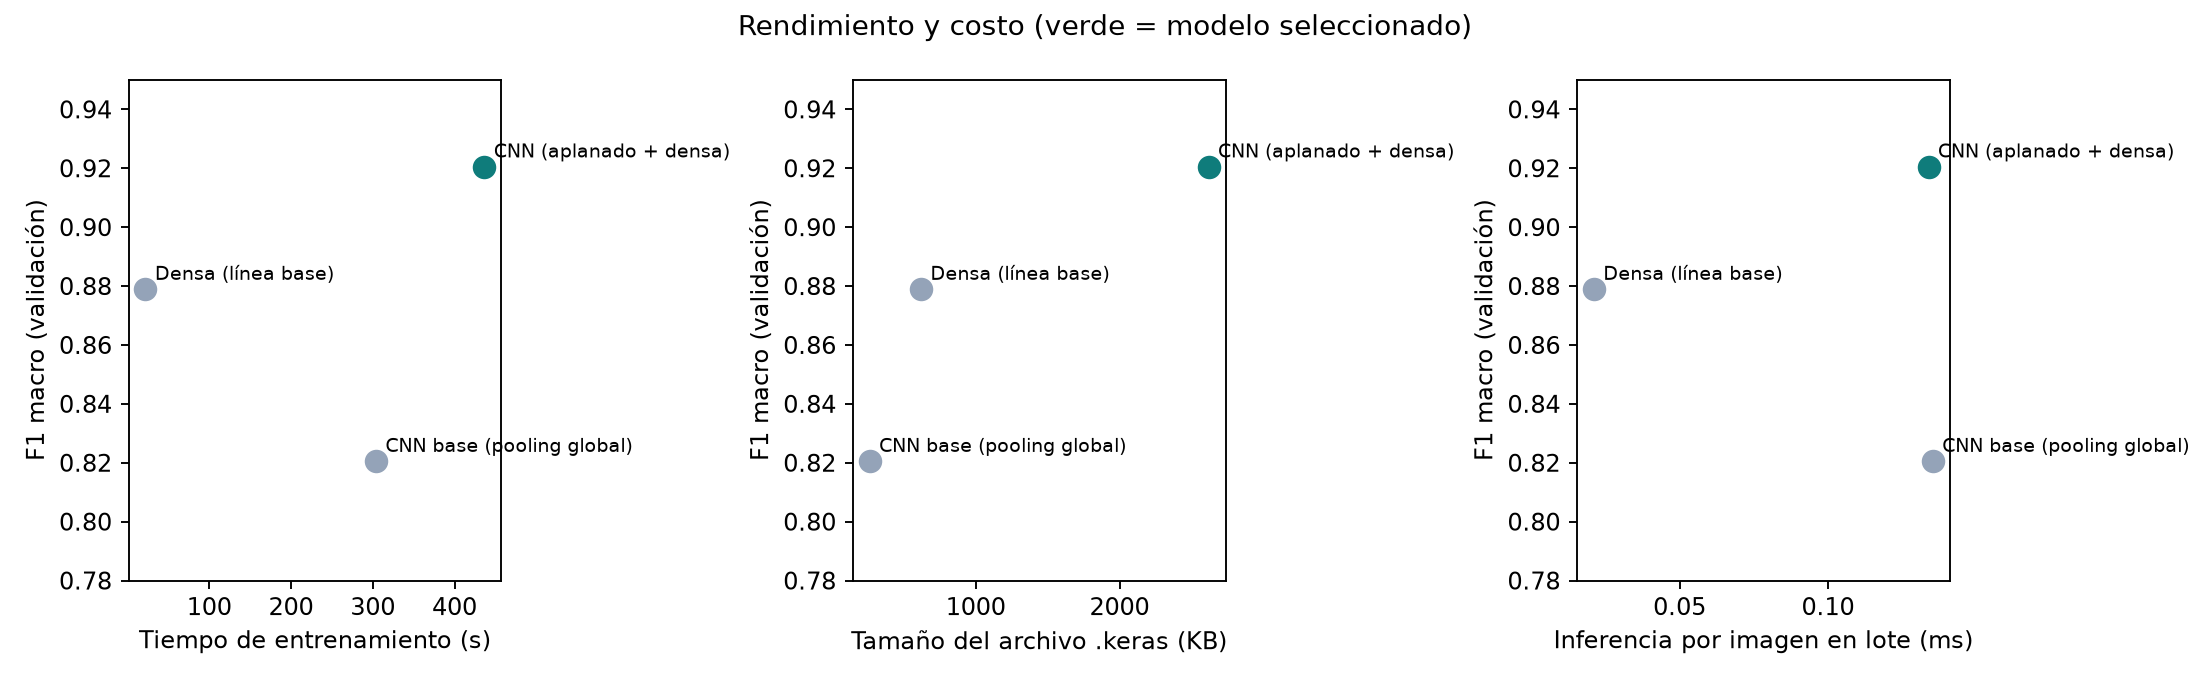

In [10]:
display(Image(REPORTS / "fig_cost_tradeoff.png", width=950))

## 7. Robustez ante perturbaciones (insumo de la Model Card)

In [11]:
results["robustness"].round(4)

,scenario,accuracy,f1_macro
0,original,0.9221,0.9213
1,ruido gaussiano σ=0.10,0.8693,0.8692
2,desplazamiento 3 px,0.4867,0.4877
3,contraste 50 %,0.8917,0.8900
4,colores invertidos,0.2146,0.1349


## 8. Conclusiones (observación → evidencia → interpretación → decisión)

**Observación.** La CNN con capa densa supera a la línea base densa y a la CNN del proyecto base en validación y en prueba (F1 macro ≈ 0.92 frente a ≈ 0.87 y ≈ 0.82).

**Evidencia.** Los intervalos bootstrap no se solapan y McNemar rechaza la igualdad con amplio margen. Las curvas muestran que la CNN base todavía no converge en 15 épocas: el pooling global reduce cada mapa 7×7 a un número y pierde la posición de rasgos como cuellos o mangas.

**Interpretación.** La convolución aporta frente al modelo denso, pero la cabeza del modelo importa tanto como los filtros. Los errores se concentran en prendas superiores (Camisa ↔ Camiseta/top, Abrigo, Suéter), donde varias imágenes son ambiguas incluso para una persona. El modelo es frágil ante desplazamientos e inversión de colores.

**Decisión.** Se selecciona `cnn`: gana ≈ 5 puntos de F1 a cambio de ≈ 20 veces más tiempo de entrenamiento en CPU, 4 veces más parámetros que la línea base y una latencia de pocos milisegundos por imagen, aceptable para uso por lotes. Las condiciones y límites de uso se documentan en `MODEL_CARD.md`.

In [12]:
print(json.dumps(results["environment"], indent=2))

{
  "python": "3.12.13",
  "platform": "Linux-6.18.44-fc-v71-x86_64-with-glibc2.39",
  "processor": "x86_64",
  "cpu_count": 1,
  "tensorflow": "2.21.0",
  "gpu": [],
  "scikit_learn": "1.9.1",
  "numpy": "2.5.3"
}
